# 配列の先頭をいじると，なぜ遅いのか

第3回では，キューを配列で素朴に実装すると
**先頭の取り出しが $O(n)$ になってしまう**ことを見た。
だから**リングバッファ**を使う，という話だった。

ここでは，その $O(n)$ を実際に測って確かめる。
計算量の違いは，紙の上では記号の差でしかないが，
動かすと**桁の違い**として目に見える。

上のセルから順に実行していけばよい。
数値は計算機によって変わるので，自分の環境で出た値を見てほしい。

## 準備

図に日本語を出すための設定である。中身は読み飛ばしてよい。

In [1]:
# 図の準備。手元でも Colab でも動くようにしてある
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager


def japanese_font():
    """日本語が出るフォント名を返す。無ければ入れる（Colab 用）。"""
    for name in ("IPAexGothic", "Noto Sans CJK JP", "IPAPGothic",
                 "Hiragino Sans", "Yu Gothic", "Meiryo"):
        if any(f.name == name for f in font_manager.fontManager.ttflist):
            return name
    import glob
    import subprocess
    subprocess.run("apt-get -qq install -y fonts-ipaexfont-gothic",
                   shell=True, check=False)
    for path in glob.glob("/usr/share/fonts/**/ipaexg.ttf", recursive=True):
        font_manager.fontManager.addfont(path)
    return "IPAexGothic"


matplotlib.rcParams.update({
    "font.family": japanese_font(),
    "font.size": 11,
    "figure.figsize": (6.0, 3.6),
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.3,
    # 日本語フォントには原則マイナス記号がないため ASCII のハイフンを使う
    "axes.unicode_minus": False,
})

In [2]:
import time

print("準備ができた")

準備ができた


## 末尾に足すのと，先頭に入れるのと

Python の `list` に $n$ 個の要素を入れる。やり方を 2 つ試す。

- `a.append(x)` …… **末尾**に足す
- `a.insert(0, x)` …… **先頭**に入れる

どちらも「$n$ 個入れる」ことに変わりはない。時間を測ってみる。

In [3]:
def push_tail(n):
    """末尾に n 個足す。"""
    a = []
    for i in range(n):
        a.append(i)
    return a


def push_head(n):
    """先頭に n 個入れる。"""
    a = []
    for i in range(n):
        a.insert(0, i)
    return a


def bench(func, n, repeat=3):
    """func(n) の所要時間（秒）。何度か測って一番速かったものを返す。"""
    best = float("inf")
    for _ in range(repeat):
        start = time.perf_counter()
        func(n)
        best = min(best, time.perf_counter() - start)
    return best

In [4]:
N = 100_000

t_tail = bench(push_tail, N)
t_head = bench(push_head, N)

print(f"末尾に {N:,} 個 : {t_tail * 1000:9.1f} ミリ秒")
print(f"先頭に {N:,} 個 : {t_head * 1000:9.1f} ミリ秒")
print(f"比            : {t_head / t_tail:9.0f} 倍")

末尾に 100,000 個 :       2.9 ミリ秒
先頭に 100,000 個 :    1066.9 ミリ秒
比            :       363 倍


同じ個数を入れているのに，先頭からだと数百倍遅い。

理由は第3回で見たとおりである。
配列は番地の上で**連続して**並んでいるので，
先頭に割り込ませるには**後ろの要素を全部 1 つずつずらす**必要がある。
$k$ 個入っているところに割り込むなら $k$ 回の移動が要る。

末尾に足すほうは，空いている区画に書くだけで済む。

## $n$ を変えて測る

「数百倍遅い」だけでは $O(n)$ の証拠にならない。
定数倍が大きいだけかもしれないからである。

オーダーの違いは，**$n$ を変えたときの増え方**に出る。
ここでは **1 要素あたり**の時間を見る。$n$ を変えながら

- 1 要素あたりが変わらなければ，1 回の操作は $O(1)$
- 1 要素あたりが $n$ に比例して増えるなら，1 回の操作は $O(n)$

ということになる。先頭に割り込む操作は，すでに $k$ 個入っていれば
$k$ 個ずらすので，$O(k)$ のはずである。

In [5]:
sizes = [12_500, 25_000, 50_000, 100_000]

# 末尾のほうは 1 回がミリ秒に満たず揺れやすいので，多めに測る
tail_times = [bench(push_tail, n, repeat=15) for n in sizes]
head_times = [bench(push_head, n) for n in sizes]

print(f"{'n':>8}{'末尾 (ms)':>11}{'先頭 (ms)':>12}"
      f"{'末尾 ns/要素':>14}{'先頭 ns/要素':>14}")
for n, tail, head in zip(sizes, tail_times, head_times):
    print(f"{n:8,d}{tail * 1000:11.1f}{head * 1000:12.1f}"
          f"{tail / n * 1e9:14,.0f}{head / n * 1e9:14,.0f}")

       n    末尾 (ms)     先頭 (ms)      末尾 ns/要素      先頭 ns/要素
  12,500        0.2        16.7            19         1,338
  25,000        0.5        67.0            19         2,679
  50,000        1.0       267.8            19         5,356
 100,000        2.3      1057.1            23        10,571


右の 2 列が答えである。

- **末尾**は $n$ を 8 倍にしてもほとんど変わらない。1 回は $O(1)$ である
- **先頭**は $n$ に比例して倍々に増える。1 回は $O(n)$ である

$n$ 回くりかえすのだから，合計はそれぞれ $O(n)$ と $O(n^2)$ になる。

末尾の列もわずかに増えているが，これは計算量ではない。
配列が大きくなるとキャッシュに収まらなくなり，1 要素あたりの手間が少し重くなる。
倍々に増えるのとは桁がちがう話である。

なお `append` が $O(1)$ なのは正確には「**ならせば**」である。
なぜそう言わなければならないのかは第4回で扱う。

## 図にする

同じデータを 2 とおりの軸で描く。

- **通常のスケール** …… ふつうに描くとこう見える
- **両対数** …… 縦軸も横軸も対数にする。$t \propto n^a$ のとき傾き $a$ の直線になる

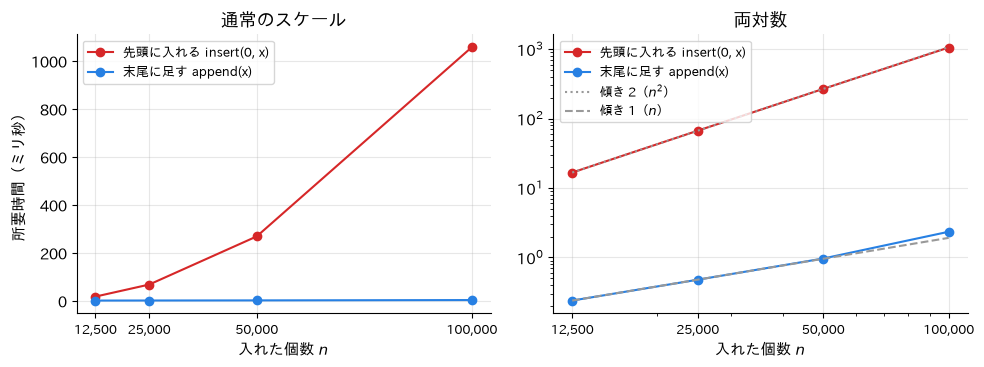

In [6]:
from matplotlib.ticker import NullFormatter

fig, axes = plt.subplots(1, 2, figsize=(10.0, 3.8))

for ax in axes:
    ax.plot(sizes, [t * 1000 for t in head_times], "o-",
            label="先頭に入れる insert(0, x)", color="#d62728")
    ax.plot(sizes, [t * 1000 for t in tail_times], "o-",
            label="末尾に足す append(x)", color="#2780e3")
    ax.set_xlabel("入れた個数 $n$")

axes[0].set_title("通常のスケール")
axes[0].set_ylabel("所要時間（ミリ秒）")
axes[0].legend(fontsize=9)

# 比べるための補助線。両対数でだけ意味があるので右にしか引かない
base_n = sizes[0]
axes[1].plot(sizes, [head_times[0] * 1000 * (n / base_n) ** 2 for n in sizes],
             ls=":", color="#999999", label="傾き 2（$n^2$）")
axes[1].plot(sizes, [tail_times[0] * 1000 * (n / base_n) for n in sizes],
             ls="--", color="#999999", label="傾き 1（$n$）")
axes[1].set_title("両対数")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].legend(fontsize=9, loc="upper left")

# 目盛りは測った n そのものにする。軸の種類を決めたあとでないと戻される
for ax in axes:
    ax.set_xticks(sizes)
    ax.set_xticklabels([f"{n:,}" for n in sizes], fontsize=9)
    ax.xaxis.set_minor_formatter(NullFormatter())

fig.tight_layout()

左の図では，先頭のほうが上に反り返り，末尾のほうは軸に貼りついて平らに見える。
だが末尾のほうも増えてはいる。縦軸が先頭の時間（1 秒近く）に合わせて伸びているので，
数ミリ秒の変化が潰れているだけである。

これが通常のスケールの弱点である。**桁の違うものを同時には見られない。**
片方をきちんと見ようとすると，もう片方が軸に貼りつくか，枠からはみ出す。

右の両対数では，どちらの点もほぼ補助線に沿っている。
傾きが 2 と 1，つまり $O(n^2)$ と $O(n)$ である。
末尾のほうが右端でわずかに上へ外れるのは，さきほどの表で見たキャッシュのぶんである。
縦軸が対数であることに注意してほしい。
いちばん右で 2 本の線は 2 目盛り以上はなれている。つまり 100 倍以上の差である。

## 素朴なキューとリングバッファ

もとの話に戻る。キューを配列で素朴に実装すると，
`dequeue` が「先頭を取り出して残りをずらす」になる。
Python では `a.pop(0)` である。

第3回では，これを避けるために**リングバッファ**を使った。
Python の標準ライブラリにある `collections.deque` も，
内側では先頭と末尾の両方を $O(1)$ で扱えるようにしてある。

$n$ 個入れて $n$ 個取り出す，という往復を測って比べる。

In [7]:
import collections


def queue_with_list(n):
    """素朴な実装。先頭の取り出しでそのつど全体をずらす。"""
    q = []
    for i in range(n):
        q.append(i)
    while q:
        q.pop(0)


def queue_with_deque(n):
    """先頭も末尾も O(1) で扱えるキュー。"""
    q = collections.deque()
    for i in range(n):
        q.append(i)
    while q:
        q.popleft()

In [8]:
print(f"{'n':>8}{'list (ms)':>12}{'deque (ms)':>12}{'比':>8}")
for n in (12_500, 25_000, 50_000, 100_000):
    t_list = bench(queue_with_list, n, repeat=1)
    t_deque = bench(queue_with_deque, n, repeat=1)
    print(f"{n:8,d}{t_list * 1000:12.1f}{t_deque * 1000:12.1f}"
          f"{t_list / t_deque:8.0f}")

       n   list (ms)  deque (ms)       比
  12,500        13.0         0.7      19
  25,000        57.9         1.4      42


  50,000       227.3         2.9      80


 100,000       929.8         5.5     168


`list` の列は $n$ を 2 倍にすると約 4 倍になる（$O(n^2)$）。
`deque` の列は約 2 倍である（$O(n)$，1 回あたり $O(1)$）。

$n$ が大きくなるほど差が開く。
これが「オーダーが違う」ということであり，
計算機を速いものに買いかえても埋まらない差である。

## まとめ

- 配列の**先頭**をいじる操作は $O(n)$ である。後ろを全部ずらすからである
- 配列の**末尾**に足す操作はならせば $O(1)$ である
- $n$ 回くりかえすと，前者は $O(n^2)$，後者は $O(n)$ になる
- 実測でも，1 要素あたりの時間が，先頭では $n$ に比例して倍々に増え，
  末尾ではほぼ一定のままだった
- 素朴なキューではなくリングバッファ（や `deque`）を使うのは，この差を避けるためである

$n = 100{,}000$ で数百倍という差は，
「定数倍の話だろう」と片づけられる大きさではない。
**どのデータ構造を選ぶか**が効くのは，こういうところである。

### 自分で試すなら

- `sizes` をもっと大きくするとどうなるか。`push_head` はすぐ数十秒になる
- `a.pop(0)` ではなく `a.pop()`（末尾）にすると，`list` でも速くなるはずである。
  それはどんなデータ構造になっているか
- `insert(0, x)` のかわりに「末尾に足してから最後に `reverse()`」だとどうなるか